### Librerías

In [1]:

from dotenv import load_dotenv

from utils.models.law_item_response import LawItemWithLaw
from utils.repository.rag_repository import *
from rich.console import Console
from rich.panel import Panel
from rich.table import Table
from rich.text import Text
from rich import box
import pandas as pd
from utils.models.law_item_response import LawItemSimplify
env_path =  ".env"
load_dotenv(dotenv_path=env_path)

C:\Users\pablo\PycharmProjects\llm_rag_fast_api\.venv\Lib\site-packages\pydantic\_internal\_config.py:373: UserWarning: Valid config keys have changed in V2:
* 'allow_population_by_field_name' has been renamed to 'validate_by_name'
* 'schema_extra' has been renamed to 'json_schema_extra'
  warnings.warn(message, UserWarning)


True

### Functiones


In [ ]:
# ============================================
# MODELO DE PREGUNTA TIPO QUIZ
# ============================================
class LegalQuizResponse(BaseModel):
    question: str = Field(description="La pregunta formulada")
    answer1: str = Field(description="Primera opción de respuesta")
    answer2: str = Field(description="Segunda opción de respuesta")
    answer3: str = Field(description="Tercera opción de respuesta")
    solution: int = Field(description="Índice de la respuesta correcta (1, 2 o 3)", ge=1, le=3)
    cites: List[LawItemSimplify] = Field(description="Citas legales usadas completas y con identificador de ley", default_factory=list)
    tip: str = Field(description="Argumentación de por qué es correcta", default="")

    model_config = ConfigDict(extra="forbid")



### Ejemplo usando el RAG service con salida predefinida

- Response: respuesta generada por el modelo
- Reasoning: razonamiento del modelo
- Citations: citas o referencias usadas por el modelo para generar la respuesta

In [ ]:
rag_service = RAGService()
result, metadata = await rag_service.process_query("mi consulta legal es el artículo 123 del código civil")
print("=== RESPUESTA ===")
print(result.response)
print("\n=== RAZONAMIENTO ===")
print(result.reasoning)
print("\n=== CITAS ===")
for i, citation in enumerate(result.citations, 1):
    print(f"{i}. {citation}")



### Ejemplo usando el RAG service con salida personalizada

In [ ]:
from typing import List
from pydantic import BaseModel, Field, ConfigDict
# Configuración
config = RAGConfig(
    model_name="gpt-5",
    agent_timeout=120,
    response_model=LegalQuizResponse
)

# Generar quiz
rag_service = RAGService(config=config)
result, metadata = await rag_service.process_query("Genera una pregunta sobre el código civil artículo 2")


In [ ]:
result

In [ ]:
metadata

### Generación de preguntas para validar el RagService

In [ ]:
from utils.repository.openai_repository import OpenAIRepository, OpenAI
openai_client = OpenAIRepository()


In [ ]:
from utils.repository.supabase_repository import SupabaseRepository

client  = SupabaseRepository()
laws = client.get_random_laws(limit=1000)

In [ ]:
results = []

for law in laws:
    response = openai_client.generate_text(
        system=(
            "Eres un estudiante de derecho que formula consultas "
            "para poner a prueba un sistema RAG. Genera una sola pregunta "
            "o caso práctico breve basado en el texto legal, "
            "sin mencionar la ley ni el artículo. "
            "Hazlo en menos de dos frases, de forma natural y no obvia."
        ),
        prompt=f"Texto legal: {law.content}"
    )
    results.append({
        "law": law,
        "response": response
    })


In [ ]:
import pandas as pd
import os

df = pd.DataFrame({
    "query": [r["response"] for r in results],
    "law_id": [r["law"].law_id for r in results],
    "law_title": [r["law"].law_title for r in results],
    "law_item_id": [r["law"].law_item_id for r in results],
    "law_item_title": [r["law"].law_item_title for r in results],
    "law_content": [r["law"].content for r in results],
    "law_identifier": [r["law"].law_identifier for r in results],
})
# crear carpeta si no existe
os.makedirs("data", exist_ok=True)

df.to_csv("data/queries_for_rag.csv", index=False)


In [ ]:
df.head()

### Metricas de evaluación del RAGService

In [2]:
# Cargar las preguntas generadas
df = pd.read_csv("data/queries_for_rag.csv")

In [6]:
df.dtypes

query             object
law_id             int64
law_title         object
law_item_id        int64
law_item_title    object
law_content       object
law_identifier    object
dtype: object

In [3]:
rag_service = RAGService(config=RAGConfig(
    model_name="gpt-5",
    agent_timeout=120,
))

result, metadata = await rag_service.process_query(df.iloc[0]["query"])

⚠️ SQL: Sin resultados para: funcionario misión temporal organismo internacional servicios especiales autorización previa interés Administración Ministerio Exteriores
⚠️ SQL: Sin resultados para: cambio de situación administrativa por servicios especiales
⚠️ SQL: Sin resultados para: autorización para cambio a servicios especiales por intereses de la Administración


🔍 Buscando similitudes para embedding de dimensión: 3072
📡 Llamando a función PostgreSQL con parámetros:
   - Límite: 10
   - Umbral similitud: 0.2
   - Incluir deprecados: False
✅ PostgreSQL retornó 10 resultados
📊 Similitudes - Max: 0.568, Min: 0.475, Avg: 0.506


In [4]:
print("=== Ley identificada ===")
print([cite.law_unic_id for cite in result.citations])
print([cite.item_title for cite in result.citations])
print([cite.law_item_id for cite in result.citations])

=== Ley identificada ===
[88, 8]
['Artículo 87', 'Artículo 6']
[8474, 2718]


### Estudio descriptivo de las preguntas

📋 INFORMACIÓN BÁSICA DEL DATASET
• Número total de registros: 1,000
• Número de columnas: 7
• Memoria utilizada: 4.66 MB

📊 INFORMACIÓN POR COLUMNA:
  • query: 1,000 únicos, 0 nulos
  • law_id: 59 únicos, 0 nulos
  • law_title: 59 únicos, 0 nulos
  • law_item_id: 1,000 únicos, 0 nulos
  • law_item_title: 673 únicos, 16 nulos
  • law_content: 996 únicos, 0 nulos
  • law_identifier: 59 únicos, 0 nulos


C:\Users\pablo\AppData\Local\Temp\ipykernel_22552\1274588987.py:120: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax9.boxplot(length_data, labels=labels, patch_artist=True)
C:\Users\pablo\AppData\Local\Temp\ipykernel_22552\1274588987.py:178: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\pablo\AppData\Local\Temp\ipykernel_22552\1274588987.py:178: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\pablo\PycharmProjects\llm_rag_fast_api\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\pablo\PycharmProjects\llm_rag_fast_api\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 1282

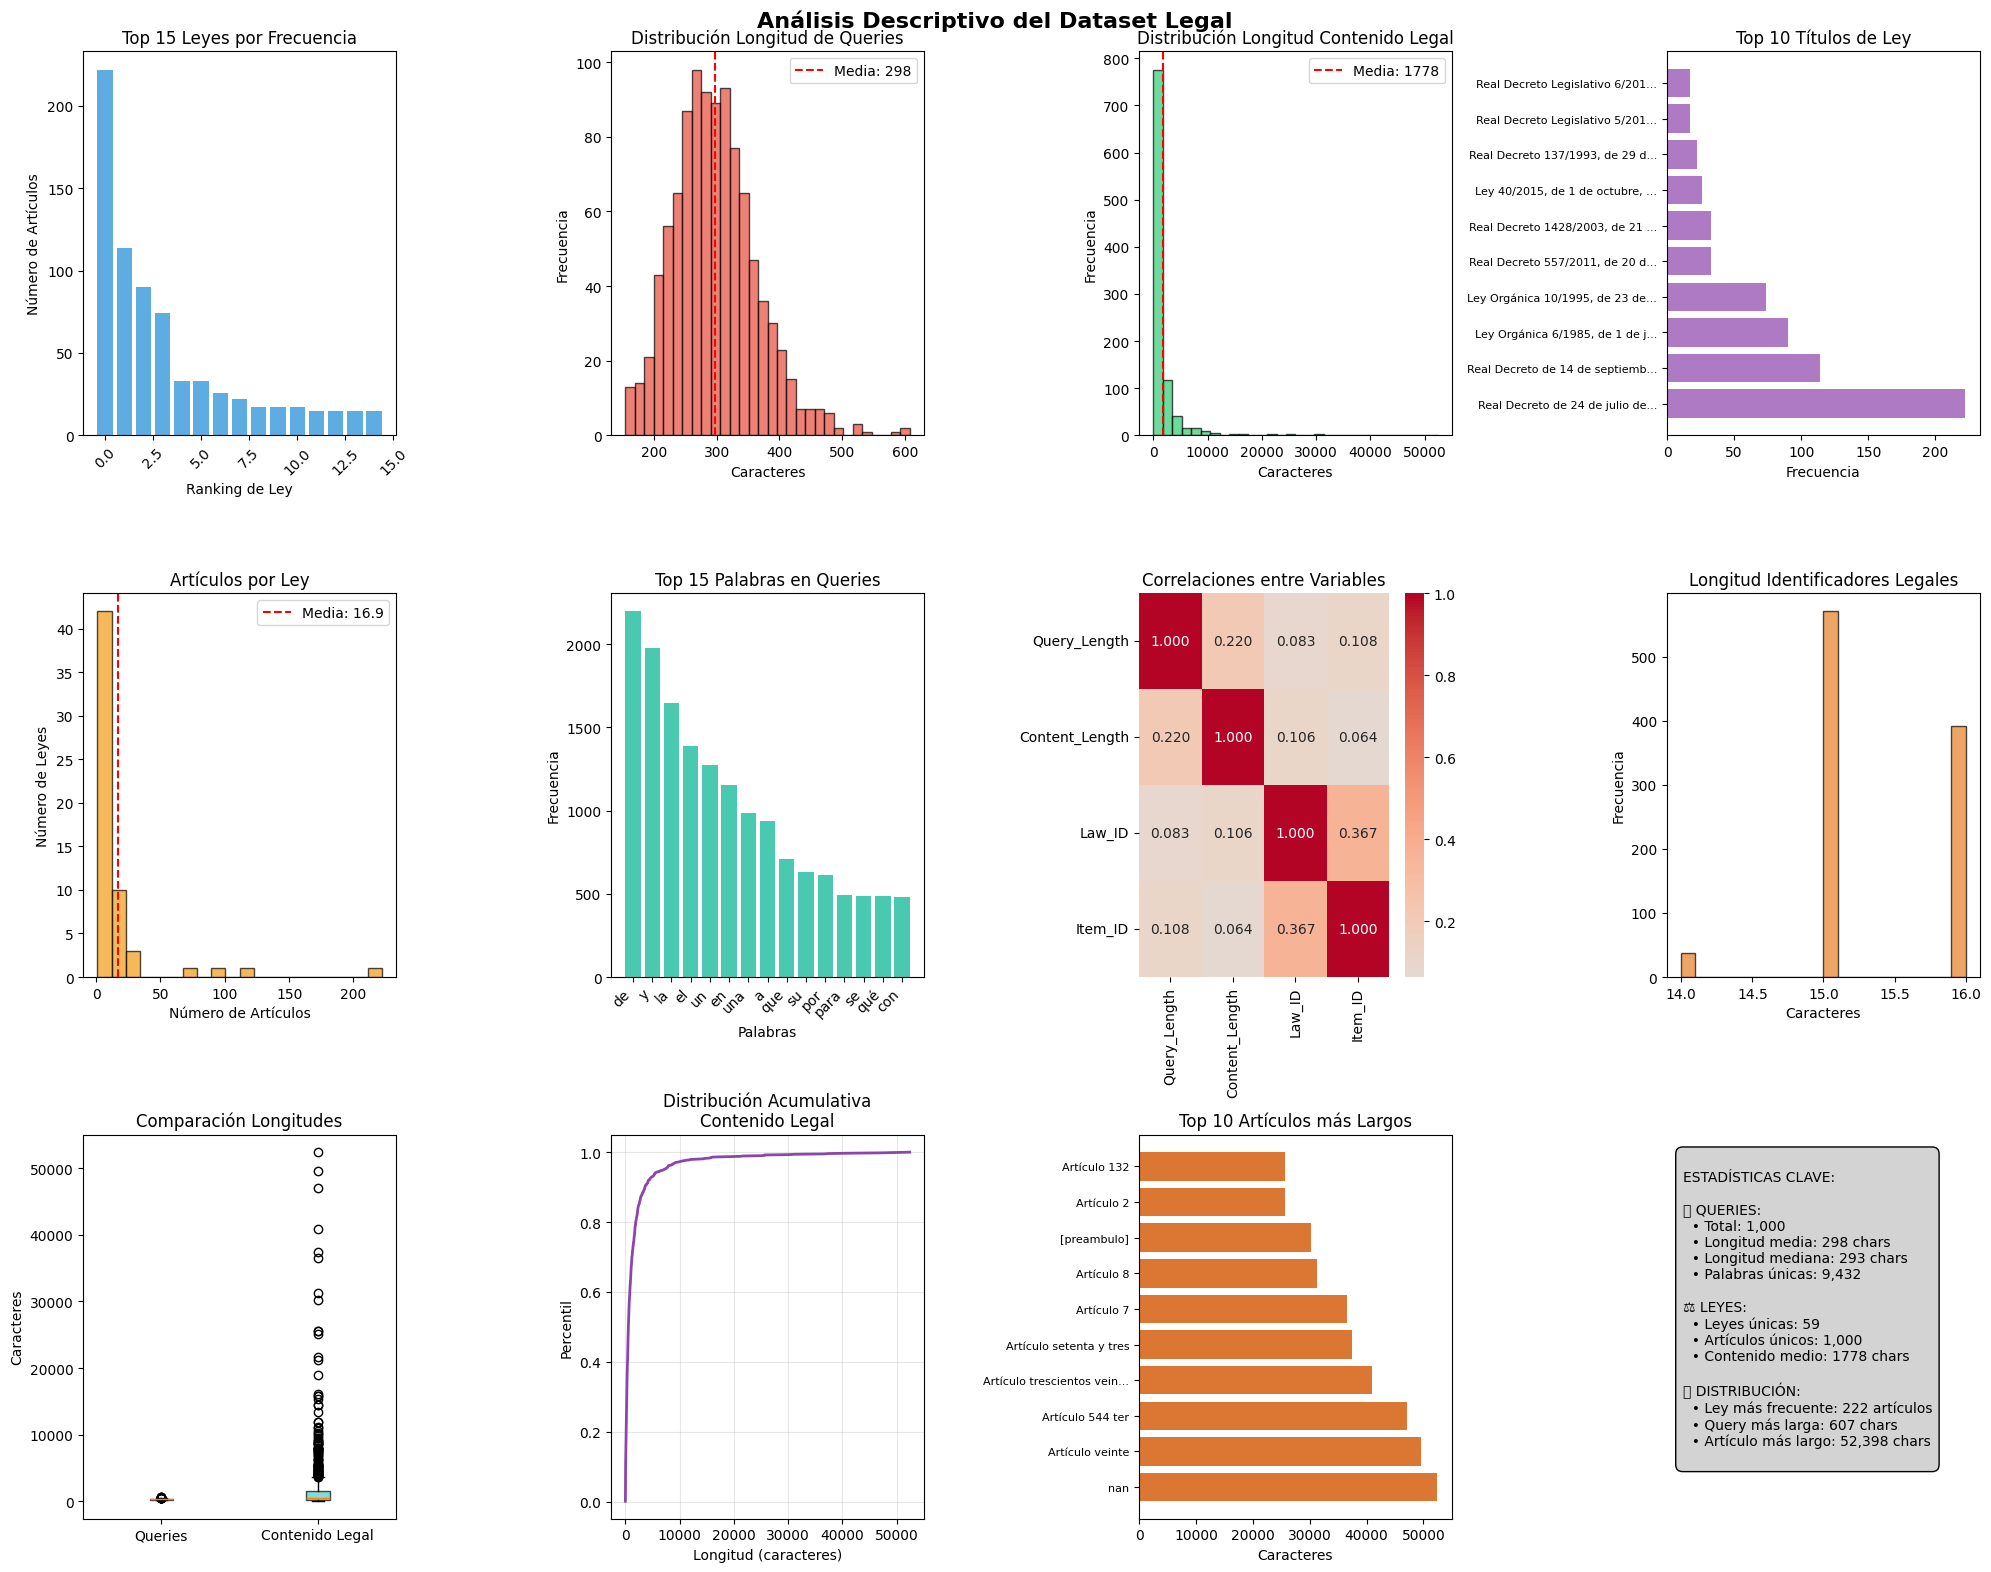


🔍 ANÁLISIS DETALLADO:
• Query más corta: 'Un senador citado como testigo solicita declarar por escrito en lugar de acudir al juzgado; ¿debe el tribunal aceptarlo o exigir su comparecencia personal?'
• Query más larga: 'Una persona extranjera solicita la autorización inicial por cuenta ajena en la plataforma de su Comu...'
• Ley con más artículos: 2 (222 artículos)
• Percentil 95 longitud queries: 414 caracteres
• Percentil 95 longitud contenido: 7063 caracteres


In [10]:
# 📊 ANÁLISIS DESCRIPTIVO DEL DATASET
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from collections import Counter

print("📋 INFORMACIÓN BÁSICA DEL DATASET")
print("="*50)
print(f"• Número total de registros: {len(df):,}")
print(f"• Número de columnas: {len(df.columns)}")
print(f"• Memoria utilizada: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Información por columna
print(f"\n📊 INFORMACIÓN POR COLUMNA:")
for col in df.columns:
    null_count = df[col].isnull().sum()
    unique_count = df[col].nunique()
    print(f"  • {col}: {unique_count:,} únicos, {null_count} nulos")

# Crear figura con subplots
fig = plt.figure(figsize=(20, 16))
fig.suptitle('Análisis Descriptivo del Dataset Legal', fontsize=16, fontweight='bold')

# 1. Distribución de leyes
ax1 = plt.subplot(3, 4, 1)
law_counts = df['law_id'].value_counts().head(15)
bars = ax1.bar(range(len(law_counts)), law_counts.values, color='#3498DB', alpha=0.8)
ax1.set_title('Top 15 Leyes por Frecuencia')
ax1.set_xlabel('Ranking de Ley')
ax1.set_ylabel('Número de Artículos')
ax1.tick_params(axis='x', rotation=45)

# 2. Distribución de longitud de queries
ax2 = plt.subplot(3, 4, 2)
query_lengths = df['query'].str.len()
ax2.hist(query_lengths, bins=30, color='#E74C3C', alpha=0.7, edgecolor='black')
ax2.set_title('Distribución Longitud de Queries')
ax2.set_xlabel('Caracteres')
ax2.set_ylabel('Frecuencia')
ax2.axvline(query_lengths.mean(), color='red', linestyle='--',
           label=f'Media: {query_lengths.mean():.0f}')
ax2.legend()

# 3. Distribución de longitud de contenido legal
ax3 = plt.subplot(3, 4, 3)
content_lengths = df['law_content'].str.len()
ax3.hist(content_lengths, bins=30, color='#2ECC71', alpha=0.7, edgecolor='black')
ax3.set_title('Distribución Longitud Contenido Legal')
ax3.set_xlabel('Caracteres')
ax3.set_ylabel('Frecuencia')
ax3.axvline(content_lengths.mean(), color='red', linestyle='--',
           label=f'Media: {content_lengths.mean():.0f}')
ax3.legend()

# 4. Top títulos de ley más frecuentes
ax4 = plt.subplot(3, 4, 4)
top_law_titles = df['law_title'].value_counts().head(10)
y_pos = np.arange(len(top_law_titles))
bars = ax4.barh(y_pos, top_law_titles.values, color='#9B59B6', alpha=0.8)
ax4.set_yticks(y_pos)
ax4.set_yticklabels([title[:30] + '...' if len(title) > 30 else title
                    for title in top_law_titles.index], fontsize=8)
ax4.set_title('Top 10 Títulos de Ley')
ax4.set_xlabel('Frecuencia')

# 5. Distribución de artículos por ley
ax5 = plt.subplot(3, 4, 5)
articles_per_law = df.groupby('law_id')['law_item_id'].nunique()
ax5.hist(articles_per_law, bins=20, color='#F39C12', alpha=0.7, edgecolor='black')
ax5.set_title('Artículos por Ley')
ax5.set_xlabel('Número de Artículos')
ax5.set_ylabel('Número de Leyes')
ax5.axvline(articles_per_law.mean(), color='red', linestyle='--',
           label=f'Media: {articles_per_law.mean():.1f}')
ax5.legend()

# 6. Palabras más comunes en queries
ax6 = plt.subplot(3, 4, 6)
all_words = ' '.join(df['query'].str.lower()).split()
word_freq = Counter(all_words)
common_words = dict(word_freq.most_common(15))
bars = ax6.bar(range(len(common_words)), list(common_words.values()),
              color='#1ABC9C', alpha=0.8)
ax6.set_title('Top 15 Palabras en Queries')
ax6.set_xlabel('Palabras')
ax6.set_ylabel('Frecuencia')
ax6.set_xticks(range(len(common_words)))
ax6.set_xticklabels(list(common_words.keys()), rotation=45, ha='right')

# 7. Mapa de calor - Correlación entre longitudes
ax7 = plt.subplot(3, 4, 7)
correlation_data = pd.DataFrame({
    'Query_Length': query_lengths,
    'Content_Length': content_lengths,
    'Law_ID': df['law_id'],
    'Item_ID': df['law_item_id']
})
corr_matrix = correlation_data.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=ax7, fmt='.3f')
ax7.set_title('Correlaciones entre Variables')

# 8. Distribución de identificadores legales
ax8 = plt.subplot(3, 4, 8)
if 'law_identifier' in df.columns and df['law_identifier'].notna().any():
    identifier_lengths = df['law_identifier'].str.len()
    ax8.hist(identifier_lengths.dropna(), bins=20, color='#E67E22', alpha=0.7, edgecolor='black')
    ax8.set_title('Longitud Identificadores Legales')
    ax8.set_xlabel('Caracteres')
    ax8.set_ylabel('Frecuencia')
else:
    ax8.text(0.5, 0.5, 'Identificadores\nno disponibles', ha='center', va='center',
            transform=ax8.transAxes, fontsize=12)
    ax8.set_title('Identificadores Legales')

# 9. Boxplot comparativo de longitudes
ax9 = plt.subplot(3, 4, 9)
length_data = [query_lengths, content_lengths]
labels = ['Queries', 'Contenido Legal']
bp = ax9.boxplot(length_data, labels=labels, patch_artist=True)
colors = ['#FF6B6B', '#4ECDC4']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax9.set_title('Comparación Longitudes')
ax9.set_ylabel('Caracteres')

# 10. Distribución acumulativa de contenido
ax10 = plt.subplot(3, 4, 10)
sorted_lengths = np.sort(content_lengths)
cumulative = np.arange(1, len(sorted_lengths) + 1) / len(sorted_lengths)
ax10.plot(sorted_lengths, cumulative, color='#8E44AD', linewidth=2)
ax10.set_title('Distribución Acumulativa\nContenido Legal')
ax10.set_xlabel('Longitud (caracteres)')
ax10.set_ylabel('Percentil')
ax10.grid(True, alpha=0.3)

# 11. Top artículos más largos
ax11 = plt.subplot(3, 4, 11)
df_temp = df.copy()
df_temp['content_length'] = df_temp['law_content'].str.len()
top_long_df = df_temp.nlargest(10, 'content_length')
top_long_articles = top_long_df['law_item_title']
article_lengths = top_long_df['content_length']
y_pos = np.arange(len(top_long_articles))
bars = ax11.barh(y_pos, article_lengths, color='#D35400', alpha=0.8)
ax11.set_yticks(y_pos)
ax11.set_yticklabels([title[:25] + '...' if len(str(title)) > 25 else str(title)
                     for title in top_long_articles], fontsize=8)
ax11.set_title('Top 10 Artículos más Largos')
ax11.set_xlabel('Caracteres')

# 12. Estadísticas resumidas
ax12 = plt.subplot(3, 4, 12)
ax12.axis('off')
stats_text = f"""
ESTADÍSTICAS CLAVE:

📊 QUERIES:
  • Total: {len(df):,}
  • Longitud media: {query_lengths.mean():.0f} chars
  • Longitud mediana: {query_lengths.median():.0f} chars
  • Palabras únicas: {len(set(all_words)):,}

⚖️ LEYES:
  • Leyes únicas: {df['law_id'].nunique():,}
  • Artículos únicos: {df['law_item_id'].nunique():,}
  • Contenido medio: {content_lengths.mean():.0f} chars

📈 DISTRIBUCIÓN:
  • Ley más frecuente: {law_counts.iloc[0]} artículos
  • Query más larga: {query_lengths.max():,} chars
  • Artículo más largo: {content_lengths.max():,} chars
"""
ax12.text(0.05, 0.95, stats_text, transform=ax12.transAxes, fontsize=10,
         verticalalignment='top', bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray"))

plt.tight_layout()
plt.show()

# Resumen textual adicional
print(f"\n🔍 ANÁLISIS DETALLADO:")
print(f"• Query más corta: '{df.loc[query_lengths.idxmin(), 'query']}'")
print(f"• Query más larga: '{df.loc[query_lengths.idxmax(), 'query'][:100]}...'")
print(f"• Ley con más artículos: {law_counts.index[0]} ({law_counts.iloc[0]} artículos)")
print(f"• Percentil 95 longitud queries: {query_lengths.quantile(0.95):.0f} caracteres")
print(f"• Percentil 95 longitud contenido: {content_lengths.quantile(0.95):.0f} caracteres")

### Validación final

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import pickle
from datetime import datetime

# Validación mejorada
law_success = 0
law_item_success = 0
both_success = 0
results = []

for i, row in df.head(100).iterrows():  # Cambia el número según necesites
    print(f"=== Pregunta {i+1} ===")
    print(f'{row["query"]}')

    result, metadata = await rag_service.process_query(row["query"])
    law_ids_found = [cite.law_unic_id for cite in result.citations]
    law_item_ids_found = [cite.law_item_id for cite in result.citations]

    law_correct = row["law_id"] in law_ids_found
    law_item_correct = row["law_item_id"] in law_item_ids_found
    both_correct = law_correct and law_item_correct

    if law_correct:
        law_success += 1
    if law_item_correct:
        law_item_success += 1
    if both_correct:
        both_success += 1

    results.append({
        'question_id': i,
        'query': row["query"],
        'expected_law_id': row["law_id"],
        'expected_law_item_id': row["law_item_id"],
        'found_law_ids': law_ids_found,
        'found_law_item_ids': law_item_ids_found,
        'law_correct': law_correct,
        'law_item_correct': law_item_correct,
        'both_correct': both_correct,
        'num_citations': len(result.citations)
    })
    print(f"✅ Ley: {law_correct}, Artículo: {law_item_correct}, Citaciones: {len(result.citations)}")
    print()

# 💾 GUARDAR RESULTADOS
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
results_data = {
    'timestamp': timestamp,
    'total_questions': len(results),
    'law_success': law_success,
    'law_item_success': law_item_success,
    'both_success': both_success,
    'detailed_results': results
}

# Guardar en pickle y CSV
with open(f'rag_validation_{timestamp}.pkl', 'wb') as f:
    pickle.dump(results_data, f)

df_results = pd.DataFrame(results)
df_results.to_csv(f'rag_validation_{timestamp}.csv', index=False)

print(f"💾 Resultados guardados:")
print(f"   • rag_validation_{timestamp}.pkl")
print(f"   • rag_validation_{timestamp}.csv")

# Métricas
total = len(results)
law_acc = (law_success/total)*100
item_acc = (law_item_success/total)*100
both_acc = (both_success/total)*100

print(f"\n📊 RESULTADOS:")
print(f"Total preguntas: {total}")
print(f"Ley correcta: {law_success} ({law_acc:.1f}%)")
print(f"Artículo correcto: {law_item_success} ({item_acc:.1f}%)")
print(f"Ambos correctos: {both_success} ({both_acc:.1f}%)")

# Gráficos
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Validación RAG', fontsize=14, fontweight='bold')

# 1. Precisión por métrica
metrics = ['Ley', 'Artículo', 'Ambos']
accuracies = [law_acc, item_acc, both_acc]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = ax1.bar(metrics, accuracies, color=colors, alpha=0.8)
ax1.set_title('Precisión (%)')
ax1.set_ylim(0, 100)
for bar, acc in zip(bars, accuracies):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 2,
            f'{acc:.1f}%', ha='center', fontweight='bold')

# 2. Distribución de citaciones
citations = [r['num_citations'] for r in results]
ax2.hist(citations, bins=max(1, len(set(citations))), alpha=0.7, color='#96CEB4')
ax2.set_title('Citaciones por Pregunta')
ax2.set_xlabel('Número de Citaciones')

# 3. Gráfico de pizza
only_law = law_success - both_success
only_item = law_item_success - both_success
neither = total - law_success - law_item_success + both_success
sizes = [both_success, only_law, only_item, neither]
labels = ['Ambos', 'Solo Ley', 'Solo Art.', 'Ninguno']
colors = ['#2ECC71', '#F39C12', '#E74C3C', '#95A5A6']
ax3.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
ax3.set_title('Distribución Resultados')

# 4. Tendencia
correct_trend = [r['both_correct'] for r in results]
ax4.plot(range(1, len(correct_trend)+1), correct_trend, 'o-', color='#9B59B6')
ax4.set_title('Precisión por Pregunta')
ax4.set_xlabel('Pregunta #')
ax4.set_ylabel('Correcto (1=Sí)')
ax4.set_ylim(-0.1, 1.1)

plt.tight_layout()
plt.show()

=== Pregunta 1 ===
Un funcionario comenzó una misión temporal en un organismo internacional y pidió pasar a servicios especiales dos semanas después; recursos humanos le dice que, si se aprueba, solo tendrá efectos desde la solicitud y que además necesitaba una autorización previa que acreditara el interés de la Administración según criterios del Ministerio de Exteriores. ¿Es correcta esta posición de la Administración en ambos puntos?


In [ ]:
# 📊 CARGAR Y VISUALIZAR RESULTADOS GUARDADOS
import pickle
import matplotlib.pyplot as plt
import pandas as pd

# Cargar resultados (cambia por tu archivo)
# timestamp = "20241211_143022"  # Ejemplo - usa tu timestamp
# with open(f'rag_validation_{timestamp}.pkl', 'rb') as f:
#     results_data = pickle.load(f)

# O usar los resultados de la celda anterior directamente:
# results_data ya está disponible

# Extraer datos
total = results_data['total_questions']
law_success = results_data['law_success']
law_item_success = results_data['law_item_success']
both_success = results_data['both_success']
results = results_data['detailed_results']

# Métricas
law_acc = (law_success/total)*100
item_acc = (law_item_success/total)*100
both_acc = (both_success/total)*100

print(f"\n📊 RESULTADOS ({results_data['timestamp']}):")
print(f"Total preguntas: {total}")
print(f"Ley correcta: {law_success} ({law_acc:.1f}%)")
print(f"Artículo correcto: {law_item_success} ({item_acc:.1f}%)")
print(f"Ambos correctos: {both_success} ({both_acc:.1f}%)")

# Gráficos
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle(f'Validación RAG - {results_data["timestamp"]}', fontsize=14, fontweight='bold')

# 1. Precisión por métrica
metrics = ['Ley', 'Artículo', 'Ambos']
accuracies = [law_acc, item_acc, both_acc]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = ax1.bar(metrics, accuracies, color=colors, alpha=0.8)
ax1.set_title('Precisión (%)')
ax1.set_ylim(0, 100)
for bar, acc in zip(bars, accuracies):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 2,
            f'{acc:.1f}%', ha='center', fontweight='bold')

# 2. Distribución de citaciones
citations = [r['num_citations'] for r in results]
ax2.hist(citations, bins=max(1, len(set(citations))), alpha=0.7, color='#96CEB4')
ax2.set_title('Citaciones por Pregunta')
ax2.set_xlabel('Número de Citaciones')

# 3. Gráfico de pizza
only_law = law_success - both_success
only_item = law_item_success - both_success
neither = total - law_success - law_item_success + both_success
sizes = [both_success, only_law, only_item, neither]
labels = ['Ambos', 'Solo Ley', 'Solo Art.', 'Ninguno']
colors = ['#2ECC71', '#F39C12', '#E74C3C', '#95A5A6']
ax3.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
ax3.set_title('Distribución Resultados')

# 4. Tendencia
correct_trend = [r['both_correct'] for r in results]
ax4.plot(range(1, len(correct_trend)+1), correct_trend, 'o-', color='#9B59B6')
ax4.set_title('Precisión por Pregunta')
ax4.set_xlabel('Pregunta #')
ax4.set_ylabel('Correcto (1=Sí)')
ax4.set_ylim(-0.1, 1.1)

plt.tight_layout()
plt.show()

# 📋 Ver casos problemáticos
print("\n🔍 ANÁLISIS DETALLADO:")
print("\n❌ Casos donde falló todo:")
for r in results:
    if not r['law_correct'] and not r['law_item_correct']:
        print(f"  • Q{r['question_id']}: {r['query'][:80]}...")

print(f"\n⚠️  Solo ley correcta ({only_law} casos):")
for r in results:
    if r['law_correct'] and not r['law_item_correct']:
        print(f"  • Q{r['question_id']}: {r['query'][:80]}...")

print(f"\n⚠️  Solo artículo correcto ({only_item} casos):")
for r in results:
    if not r['law_correct'] and r['law_item_correct']:
        print(f"  • Q{r['question_id']}: {r['query'][:80]}...")